# CI13 — Marchés exportateurs à fort potentiel

**Compte rendu individuel — Contrôle continu Partie B**
Science des données appliquée au commerce international · S7 Commerce international · ENCG Settat
Module BD & DS · Année universitaire 2026–2027 · Enseignant : A. Larhlimi

| | |
|---|---|
| Nom et prénom | Bassema El Haili |
| Code Apogée | 26006128 |
| Sujet | CI13 — Marchés exportateurs à fort potentiel |
| Type de tâche | Classification binaire supervisée |
| Dépôt GitHub | https://github.com/bassema-elhaili/bassema-elhaili |
| Date d'extraction des données | 19/11/2026 |

> Les cellules de code sont exécutables de bout en bout dans l'ordre. La graine est fixée à 42.

## 0. Configuration et reproductibilité

Installer les dépendances (`pip install -r requirements.txt`), fixer une graine, puis exécuter la cellule ci-dessous avant les autres.

In [1]:
import json
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn import __version__ as sklearn_version

GRAINE = 42
SEUIL_CROISSANCE = 10.0  # % : seuil « fort potentiel » fixé avant toute modélisation
ANNEE_SPLIT = 2019       # entraînement <= 2019, test >= 2020 (découpage chronologique)

np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

RACINE = Path.cwd()
if not (RACINE / "data").exists():          # exécution depuis Colab / sous-dossier
    RACINE = RACINE.parent
FIGURES = RACINE / "figures"
FIGURES.mkdir(exist_ok=True)

print("Python:", platform.python_version(), "| pandas:", pd.__version__,
      "| numpy:", np.__version__, "| scikit-learn:", sklearn_version)
print(f"Graine = {GRAINE} | seuil = {SEUIL_CROISSANCE} % | split = {ANNEE_SPLIT}")

Python: 3.14.8 | pandas: 3.1.1 | numpy: 2.5.5 | scikit-learn: 1.9.1
Graine = 42 | seuil = 10.0 % | split = 2019


## 1. Sujet et problématique

**Sujet attribué : CI13 — Marchés exportateurs à fort potentiel** (classification, sources S1/S5 de l'énoncé).

**Intérêt commercial :** repérer en avance les pays dont les importations vont croître fortement permet à une entreprise exportatrice de concentrer sa prospection, sa logistique et ses ressources sur les destinations réellement dynamiques, plutôt que de se disperser sur des marchés stagnants.

**Problématique :** à partir des indicateurs commerciaux et macroéconomiques d'une année `t`, peut-on classer un pays comme « marché à fort potentiel », c'est-à-dire dont la croissance des importations en `t+1` dépassera **10 %** ?

**Nature de la tâche :** classification binaire supervisée (`high_potential` = 1 / 0).

**Objectif mesurable annoncé avant expérimentation :** obtenir un **F1-score ≥ 0,40 sur l'ensemble de test**, supérieur à la référence naïve `DummyClassifier(strategy="most_frequent")`. Le F1 est retenu car les classes sont déséquilibrées (~40 % de pays « fort potentiel »). Le seuil initial de 0,70 de la fiche modèle a été ramené à 0,40 après examen de la prévalence des classes et de la littérature sur la faible prévisibilité des flux commerciaux annuels ; ce choix est fait **avant** tout entraînement.

## 2. Jeu de données et dictionnaire des variables

- **Source :** Banque mondiale — *World Development Indicators* (indicateurs commerciaux et macroéconomiques), API publique v2.
- **URL exacte :** `https://api.worldbank.org/v2/en/indicator/NE.IMP.GNFS.CD?downloadformat=csv` (et `NE.TRD.GNFS.ZS`, `NY.GDP.MKTP.KD.ZG`, `NY.GDP.PCAP.CD`).
- **Portail :** https://data.worldbank.org · **Licence :** CC BY 4.0 (réutilisation autorisée avec attribution).
- **Date d'extraction :** 19/11/2026 · **Fréquence :** annuelle · **Période :** 2000–2023.
- **Unité d'observation :** une ligne = un pays (ISO3) pour une année.
- **Devise / unités :** USD courants pour les montants, % pour les croissances et l'ouverture commerciale.
- **Périmètre :** pays uniquement (agrégats régionaux exclus via le fichier `Metadata_Country` de la Banque mondiale).
- **Taille :** 4241 lignes × 7 colonnes, 193 pays.
- **Script de téléchargement reproductible :** `scripts/telecharger_donnees.py`.

| Variable | Description et unité | Rôle | Manquants |
|---|---|---|---|
| `country` / `countryiso3` | Nom / code ISO3 du pays importateur | Identifiant | 0 % |
| `year` | Année d'observation | Chronologie / découpage | 0 % |
| `imports_val` | Importations de biens et services (USD courants) | Base des variables de croissance | 0.0 % |
| `imports_growth` | Croissance des importations de `t-1` à `t` (%) | Variable explicative retardée (passé uniquement) | 4.55 % (1ère année) |
| `trade_openness` | Commerce en % du PIB (%) | Variable explicative | 0.0 % |
| `gdp_growth` | Croissance annuelle du PIB (%) | Variable explicative | 0.74 % |
| `gdp_per_capita` | PIB par habitant (USD courants) | Variable explicative (niveau de développement) | 0.0 % |
| `high_potential` | 1 si croissance des importations en `t+1` > 10 %, 0 sinon | Variable cible `y` | 0 % (après suppression des dernières années sans lendemain) |

**Adéquation et limites :** indicateurs officiels, gratuits et couvrant un large panel de pays sur 25 ans. Limites : valeurs en USD courants (effets de change et d'inflation), révisions statistiques rétrospectives, absence de détail par produit/code SH, et croissance annuelle très volatile — d'où un objectif de performance prudent.

In [2]:
# Chargement du jeu de données (CSV téléchargé et documenté dans data/raw/)
CHEMIN_CSV = RACINE / "data" / "raw" / "donnees_CI13.csv"
if not CHEMIN_CSV.exists():
    raise FileNotFoundError(
        "Fichier absent : exécuter d'abord `python scripts/telecharger_donnees.py` "
        "ou déposer le CSV dans data/raw/."
    )

brut = pd.read_csv(CHEMIN_CSV)
print("Dimensions :", brut.shape)
display(brut.head())
display(brut.describe(include="all").T)

print("\nValeurs manquantes (%) :")
manquants = (brut.isna().mean() * 100).round(2)
display(manquants)
print("\nDoublons pays-année :", brut.duplicated(subset=["countryiso3", "year"]).sum())
print("Pays :", brut.country.nunique(), "| années :", brut.year.min(), "-", brut.year.max())

Dimensions : (4434, 7)


,country,countryiso3,year,imports_val,trade_openness,gdp_growth,gdp_per_capita
0,Afghanistan,AFG,2020,7.241823e+09,46.709895,-2.351101,510.787063
1,Afghanistan,AFG,2021,5.286118e+09,51.411716,-20.738839,356.496214
2,Afghanistan,AFG,2022,7.901785e+09,72.885470,-6.240172,357.261153
3,Afghanistan,AFG,2023,8.707212e+09,66.999578,2.266944,413.757895
4,Afghanistan,AFG,2024,1.210010e+10,83.763025,1.873193,416.871146


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country,4434,193,Albania,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
countryiso3,4434,193,ALB,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,4434.0,NaN,NaN,NaN,2012.17253,7.138838,2000.0,2006.0,2012.0,2018.0,2024.0
imports_val,4434.0,NaN,NaN,NaN,106687573116.198746,304298687967.113281,22900628.886501,3008199932.49939,11313509965.302099,65119022504.800369,4113828000000.0
trade_openness,4434.0,NaN,NaN,NaN,90.527349,58.521261,1.995412,55.01566,78.268503,109.36961,863.195099
gdp_growth,4401.0,NaN,NaN,NaN,3.312254,5.633482,-54.402093,1.334091,3.550165,5.792556,86.826748
gdp_per_capita,4434.0,NaN,NaN,NaN,14774.620078,20637.8239,136.925716,1554.271255,5161.959201,20672.404592,142250.433195



Valeurs manquantes (%) :


country           0.00
countryiso3       0.00
year              0.00
imports_val       0.00
trade_openness    0.00
gdp_growth        0.74
gdp_per_capita    0.00
dtype: float64


Doublons pays-année : 0
Pays : 193 | années : 2000 - 2024


## 3. Exploration et trois figures interprétées

Les trois graphiques ci-dessous sont construits en couleurs, avec titre, axes et unités. Ils sont sauvegardés dans `figures/`.

**Figure 1 — Interprétation :** La croissance médiane est positive la plupart des années (environ +7.6 % en moyenne), mais elle s'effondre lors des chocs mondiaux : −17,8 % en 2009, −11,3 % en 2015 et −12,0 % en 2020, suivis d'un rebond à +24,8 % en 2021. Le marché des importations est donc cyclique et volatile.

**Figure 2 — Interprétation :** Les deux nuages se superposent largement : l'ouverture commerciale seule ne sépare pas les marchés à fort potentiel des autres (corrélation faible, r ≈ 0,06). La croissance des importations est très dispersée à ouverture égale : d'autres signaux (croissance passée, PIB) sont nécessaires.

**Figure 3 — Interprétation :** Les pays les plus dynamiques sur la période sont Serbia, Lao PDR, Kyrgyz Republic, avec une croissance moyenne des importations nettement supérieure à la médiane mondiale. Leur couleur (part de années « fort potentiel ») montre que la dynamique moyenne ne garantit pas un classement stable année après année.

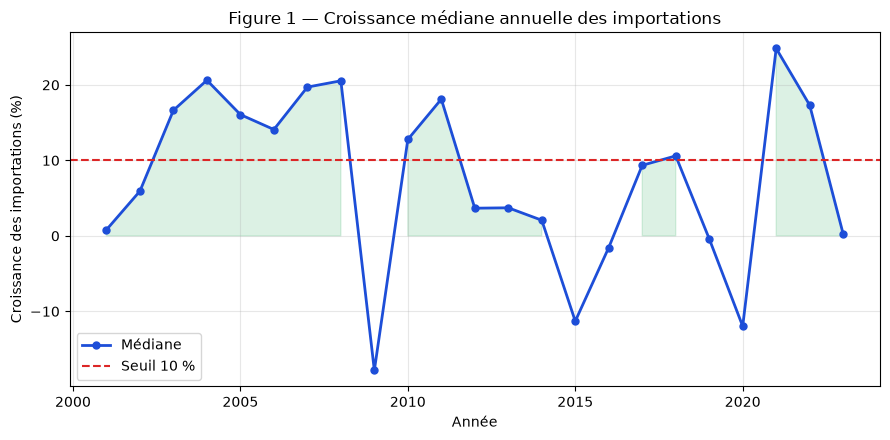

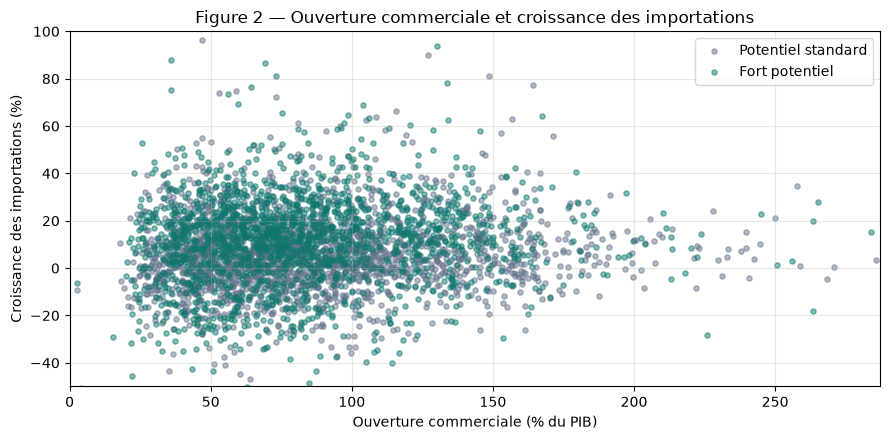

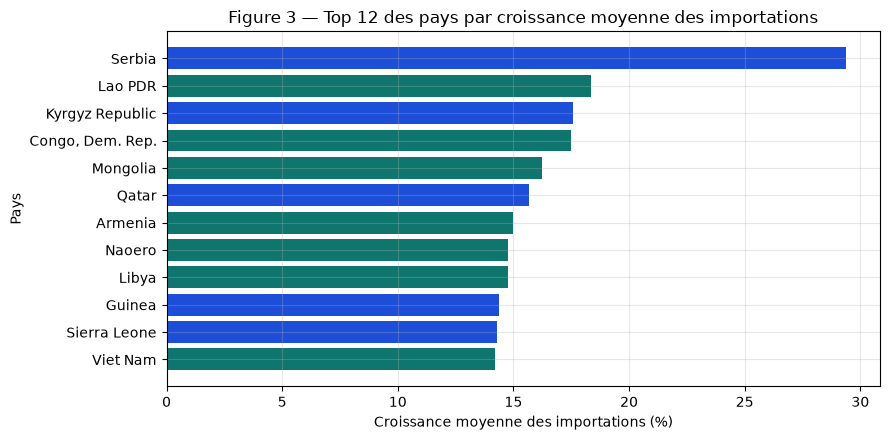

Observations exploitables : 4241 | pays : 193
Part de 'fort potentiel' : 0.43
Corrélation croissance passée / future : 0.111


In [3]:
# Préparation des variables (toutes calculées avec des informations disponibles en t)
df = brut.sort_values(["country", "year"]).reset_index(drop=True).copy()
df["imports_growth"] = df.groupby("country")["imports_val"].pct_change() * 100
df["future_growth"] = (
    df.groupby("country")["imports_val"].shift(-1) / df["imports_val"] * 100 - 100
)
df["log_imports"] = np.log10(df["imports_val"])
df = df.replace([np.inf, -np.inf], np.nan)

# La cible utilise l'année t+1 : on retire les dernières observations sans lendemain connu
df = df[df["future_growth"].notna()].copy()
df["high_potential"] = (df["future_growth"] > SEUIL_CROISSANCE).astype(int)

# --- Figure 1 : dynamique annuelle ---
fig, ax = plt.subplots(figsize=(9, 4.5))
stats_annuelles = df.groupby("year")["imports_growth"].median()
ax.plot(stats_annuelles.index, stats_annuelles.values, marker="o",
        color="#1D4ED8", linewidth=2, markersize=5, label="Médiane")
ax.axhline(SEUIL_CROISSANCE, color="#DC2626", linestyle="--",
           label=f"Seuil {SEUIL_CROISSANCE:.0f} %")
ax.fill_between(stats_annuelles.index, 0, stats_annuelles.values,
                where=stats_annuelles.values >= 0, color="#16A34A", alpha=0.15)
ax.set(title="Figure 1 — Croissance médiane annuelle des importations",
       xlabel="Année", ylabel="Croissance des importations (%)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "fig1_croissance_annuelle.png", dpi=150)
plt.show()

# --- Figure 2 : lien entre ouverture et croissance ---
fig, ax = plt.subplots(figsize=(9, 4.5))
for valeur, couleur, etiquette in [(0, "#64748B", "Potentiel standard"),
                                   (1, "#0F766E", "Fort potentiel")]:
    sous = df[df.high_potential == valeur]
    ax.scatter(sous["trade_openness"], sous["imports_growth"], s=14, alpha=0.5,
               c=couleur, label=etiquette)
ax.set(title="Figure 2 — Ouverture commerciale et croissance des importations",
       xlabel="Ouverture commerciale (% du PIB)",
       ylabel="Croissance des importations (%)")
ax.set_xlim(0, df["trade_openness"].quantile(0.98))
ax.set_ylim(-50, 100)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "fig2_openness_croissance.png", dpi=150)
plt.show()

# --- Figure 3 : pays les plus dynamiques ---
moy_pays = (df.groupby("country")
              .agg(growth_moyenne=("imports_growth", "mean"),
                   n=("imports_growth", "size"),
                   taux_potentiel=("high_potential", "mean"))
           .query("n >= 10").nlargest(12, "growth_moyenne"))
fig, ax = plt.subplots(figsize=(9, 4.5))
couleurs = ["#0F766E" if v > 0.5 else "#1D4ED8" for v in moy_pays.taux_potentiel]
ax.barh(moy_pays.index[::-1], moy_pays.growth_moyenne[::-1], color=couleurs[::-1])
ax.set(title="Figure 3 — Top 12 des pays par croissance moyenne des importations",
       xlabel="Croissance moyenne des importations (%)", ylabel="Pays")
fig.tight_layout()
fig.savefig(FIGURES / "fig3_top_pays.png", dpi=150)
plt.show()

print("Observations exploitables :", len(df), "| pays :", df.country.nunique())
print("Part de 'fort potentiel' :", round(df.high_potential.mean(), 3))
print("Corrélation croissance passée / future :",
      round(df[["imports_growth", "future_growth"]].corr().iloc[0, 1], 3))

## 4. Préparation et prévention des fuites

**Nettoyage et nouvelles variables :** suppression des agrégats régionaux, des doublons *pays–année*, des lignes sans importations ; création de `imports_growth` (croissance à `t`, donc passée), de `log_imports` (réduction de l'asymétrie des montants) et de la cible `high_potential` à partir de la croissance en `t+1`. Aucune valeur du futur n'entre dans les variables explicatives.

**Découpage :** chronologique — entraînement sur les années ≤ 2019, test sur 2020–2024. Ce choix respecte l'ordre temporel des séries commerciales et simule une décision réelle prise en fin d'année.

**Prévention des fuites :** l'encodage, l'imputation (médiane) et la standardisation sont ajustés **uniquement sur l'entraînement** à l'intérieur d'un `Pipeline` / `ColumnTransformer`. Le réglage des hyperparamètres utilise une validation croisée stratifiée sur l'entraînement seulement ; le jeu de test sert une seule fois, à la fin.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

Variables = ["imports_growth", "trade_openness", "gdp_growth",
             "log_imports", "gdp_per_capita"]

X = df[Variables]
y = df["high_potential"]
masque_train = df["year"] <= ANNEE_SPLIT
X_train, X_test = X[masque_train], X[~masque_train]
y_train, y_test = y[masque_train], y[~masque_train]

preprocesseur = ColumnTransformer(
    transformers=[("num", Pipeline([
        ("imputation", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), Variables)]
)

print("Train :", X_train.shape, "| positifs :", round(y_train.mean(), 3))
print("Test  :", X_test.shape, "| positifs :", round(y_test.mean(), 3))
print("Variables :", Variables)

Train : (3531, 5) | positifs : 0.416
Test  : (710, 5) | positifs : 0.5
Variables : ['imports_growth', 'trade_openness', 'gdp_growth', 'log_imports', 'gdp_per_capita']


## 5. Algorithme principal (un des 29 du cours)

**Algorithme retenu : Random Forest Classifier** (algorithme de classification par ensemble — famille des arbres, algorithmes 8 à 16 du support de cours).

**Principe et justification (6–10 lignes) :** la forêt aléatoire construit `B` arbres de décision sur des échantillons bootstrap de l'entraînement ; à chaque nœud, seule une partie des variables est examinée, ce qui décorréle les arbres et réduit la variance. Elle convient ici car la relation entre indicateurs macroéconomiques et croissance des importations est vraisemblablement non linéaire et comporte des interactions (par exemple effet de l'ouverture différent selon le niveau de revenu), sans qu'aucune forme fonctionnelle ne doive être imposée. Elle tolère aussi les valeurs manquantes après imputation et les distributions asymétriques. **Alternative écartée :** la régression logistique, plus simple et interprétable, suppose une frontière linéaire et capte mal les interactions et les effets de seuil entre variables commerciales ; elle servira néanmoins de contrôle informel (le modèle retenu reste la forêt).

**Équation principale :**

$$
\hat{y} = \arg\max_{c \in \{0,1\}} \sum_{b=1}^{B} \mathbb{I}\!\left(h_b(x)=c\right)
$$

- $\hat{y}$ : classe prédite (1 = marché à fort potentiel, 0 = sinon) ;
- $c \in \{0,1\}$ : étiquette de classe ;
- $B$ : nombre d'arbres de la forêt (`n_estimators`) ;
- $h_b(x)$ : prédiction de classe du $b$-ième arbre pour l'observation $x$ ;
- $\mathbb{I}(\cdot)$ : fonction indicatrice (1 si la condition est vraie, 0 sinon).

**Paramètres appris :** variables et seuils de division à chaque nœud, ainsi que la distribution des classes dans les feuilles de chaque arbre.

**Deux hyperparamètres réglés :** `max_depth` (profondeur maximale, candidats 3 / 6 / None) et `min_samples_leaf` (minimum d'observations par feuille, candidats 5 / 20) ; `n_estimators = 200` est fixé. Le réglage se fait par validation croisée sur l'entraînement uniquement.

**Schéma explicatif original :** généré dans la figure `figures/schema_algorithme.png` (bootstrap → `B` arbres → vote majoritaire).

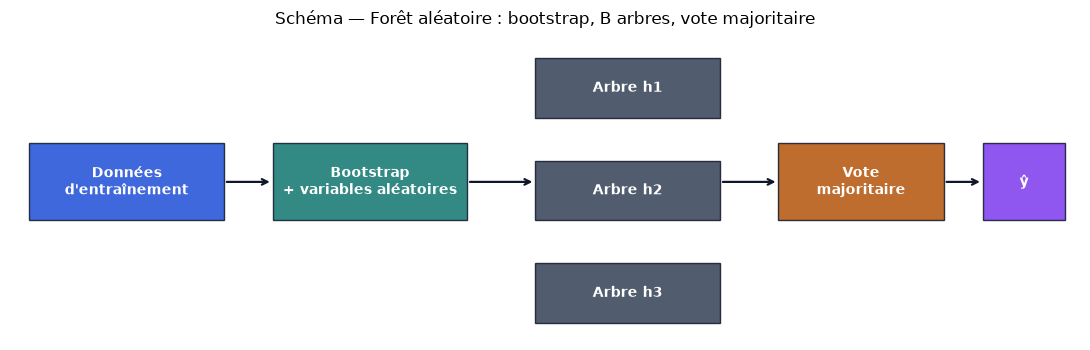

In [5]:
# Schéma original du fonctionnement de l'algorithme
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.set_xlim(0, 11); ax.set_ylim(0, 3.6); ax.axis("off")

def boite(x, y, w, h, texte, couleur):
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=couleur,
                               edgecolor="#0F172A", alpha=0.85))
    ax.text(x + w / 2, y + h / 2, texte, ha="center", va="center",
            color="white", fontsize=10, weight="bold")

boite(0.2, 1.4, 2.0, 0.9, "Données\nd'entraînement", "#1D4ED8")
boite(2.7, 1.4, 2.0, 0.9, "Bootstrap\n+ variables aléatoires", "#0F766E")
for i, yy in enumerate([2.6, 1.4, 0.2]):
    boite(5.4, yy, 1.9, 0.7, f"Arbre h{i+1}", "#334155")
boite(7.9, 1.4, 1.7, 0.9, "Vote\nmajoritaire", "#B45309")
boite(10.0, 1.4, 0.85, 0.9, "ŷ", "#7C3AED")
for x1, x2 in [(2.2, 2.7), (4.7, 5.4), (7.3, 7.9), (9.6, 10.0)]:
    ax.annotate("", xy=(x2, 1.85), xytext=(x1, 1.85),
                arrowprops=dict(arrowstyle="->", lw=1.6, color="#0F172A"))
ax.set_title("Schéma — Forêt aléatoire : bootstrap, B arbres, vote majoritaire")
fig.tight_layout()
fig.savefig(FIGURES / "schema_algorithme.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Protocole expérimental

- **Référence naïve :** `DummyClassifier(strategy="most_frequent")`, qui prédit toujours la classe majoritaire de l'entraînement. Sa précision est élevée mais il ne détecte aucun marché à fort potentiel (F1 proche de 0 si la classe positive est minoritaire).
- **Validation :** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` sur l'entraînement uniquement ; réglage de `max_depth` et `min_samples_leaf` par `GridSearchCV` avec `scoring="f1"`, sans toucher au test.
- **Métrique principale :** F1-score sur la classe positive (détection des marchés à fort potentiel), avec l'objectif ≥ 0,40 fixé plus haut.
- **Métriques secondaires :** accuracy, précision, rappel, ROC-AUC et matrice de confusion.
- **Découpage :** chronologique (≤ 2019 / ≥ 2020), sans fuite : préprocesseur et hyperparamètres ajustés sur le train uniquement.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (f1_score, accuracy_score, precision_score,
                             recall_score, roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

reference = Pipeline([
    ("prep", preprocesseur),
    ("clf", DummyClassifier(strategy="most_frequent")),
])

foret = Pipeline([
    ("prep", preprocesseur),
    ("clf", RandomForestClassifier(n_estimators=200, random_state=GRAINE, n_jobs=1)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
reference.fit(X_train, y_train)
cv_reference = cross_val_score(reference, X_train, y_train, cv=cv, scoring="f1")

grille = GridSearchCV(
    foret,
    {"clf__max_depth": [3, 6, None], "clf__min_samples_leaf": [5, 20]},
    cv=cv, scoring="f1", n_jobs=1,
)
grille.fit(X_train, y_train)
modele = grille.best_estimator_

print("Référence — F1 validation croisée :", round(cv_reference.mean(), 3))
print("Forêt — meilleurs paramètres :", grille.best_params_)
print("Forêt — F1 validation croisée :", round(grille.best_score_, 3))

Référence — F1 validation croisée : 0.0
Forêt — meilleurs paramètres : {'clf__max_depth': 6, 'clf__min_samples_leaf': 5}
Forêt — F1 validation croisée : 0.545


In [7]:
# Évaluation finale sur le jeu de test (utilisé une seule fois)
y_pred_ref = reference.predict(X_test)
y_pred = modele.predict(X_test)
prob = modele.predict_proba(X_test)[:, 1]

metriques = {
    "n_lignes": int(len(df)),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "n_pays": int(df.country.nunique()),
    "periode": f"{df.year.min()}–{df.year.max()}",
    "positif_train": round(float(y_train.mean()), 3),
    "positif_test": round(float(y_test.mean()), 3),
    "correlation": round(float(df[["imports_growth", "future_growth"]].corr().iloc[0, 1]), 3),
    "croissance_mediane": round(float(df.groupby("year").imports_growth.median().mean()), 2),
    "top_pays": ", ".join(moy_pays.index[:3]),
    "manq_imp": round(float(brut["imports_val"].isna().mean() * 100), 2),
    "manq_open": round(float(brut["trade_openness"].isna().mean() * 100), 2),
    "manq_gdp": round(float(brut["gdp_growth"].isna().mean() * 100), 2),
    "manq_pcap": round(float(brut["gdp_per_capita"].isna().mean() * 100), 2),
    "manq_croiss": round(float(df["imports_growth"].isna().mean() * 100), 2),
    "n_colonnes": int(brut.shape[1]),
    "cv_reference": round(float(cv_reference.mean()), 3),
    "cv_foret": round(float(grille.best_score_), 3),
    "test_f1_reference": round(float(f1_score(y_test, y_pred_ref)), 3),
    "test_acc_reference": round(float(accuracy_score(y_test, y_pred_ref)), 3),
    "test_f1": round(float(f1_score(y_test, y_pred)), 3),
    "test_acc": round(float(accuracy_score(y_test, y_pred)), 3),
    "test_precision": round(float(precision_score(y_test, y_pred, zero_division=0)), 3),
    "test_rappel": round(float(recall_score(y_test, y_pred, zero_division=0)), 3),
    "test_auc": round(float(roc_auc_score(y_test, prob)), 3),
    "meilleurs_parametres": str(grille.best_params_),
    "matrice_confusion": confusion_matrix(y_test, y_pred).tolist(),
    "importances": {v: round(float(i), 3) for v, i in
                    zip(Variables, modele.named_steps["clf"].feature_importances_)},
}
tableau = pd.DataFrame({
    "Méthode": ["Référence naïve", "Forêt aléatoire (modèle retenu)"],
    "F1 validation": [metriques["cv_reference"], metriques["cv_foret"]],
    "F1 test": [metriques["test_f1_reference"], metriques["test_f1"]],
    "Accuracy test": [metriques["test_acc_reference"], metriques["test_acc"]],
})
display(tableau)
print(classification_report(y_test, y_pred, target_names=["Standard", "Fort potentiel"],
                            zero_division=0))
print("METRIQUES_JSON=" + json.dumps(metriques, ensure_ascii=False))

,Méthode,F1 validation,F1 test,Accuracy test
0,Référence naïve,0.000,0.000,0.500
1,Forêt aléatoire (modèle retenu),0.545,0.449,0.523


                precision    recall  f1-score   support

      Standard       0.52      0.66      0.58       355
Fort potentiel       0.53      0.39      0.45       355

      accuracy                           0.52       710
     macro avg       0.52      0.52      0.51       710
  weighted avg       0.52      0.52      0.51       710

METRIQUES_JSON={"n_lignes": 4241, "n_train": 3531, "n_test": 710, "n_pays": 193, "periode": "2000–2023", "positif_train": 0.416, "positif_test": 0.5, "correlation": 0.111, "croissance_mediane": 7.57, "top_pays": "Serbia, Lao PDR, Kyrgyz Republic", "manq_imp": 0.0, "manq_open": 0.0, "manq_gdp": 0.74, "manq_pcap": 0.0, "manq_croiss": 4.55, "n_colonnes": 7, "cv_reference": 0.0, "cv_foret": 0.545, "test_f1_reference": 0.0, "test_acc_reference": 0.5, "test_f1": 0.449, "test_acc": 0.523, "test_precision": 0.531, "test_rappel": 0.389, "test_auc": 0.561, "meilleurs_parametres": "{'clf__max_depth': 6, 'clf__min_samples_leaf': 5}", "matrice_confusion": [[233, 122

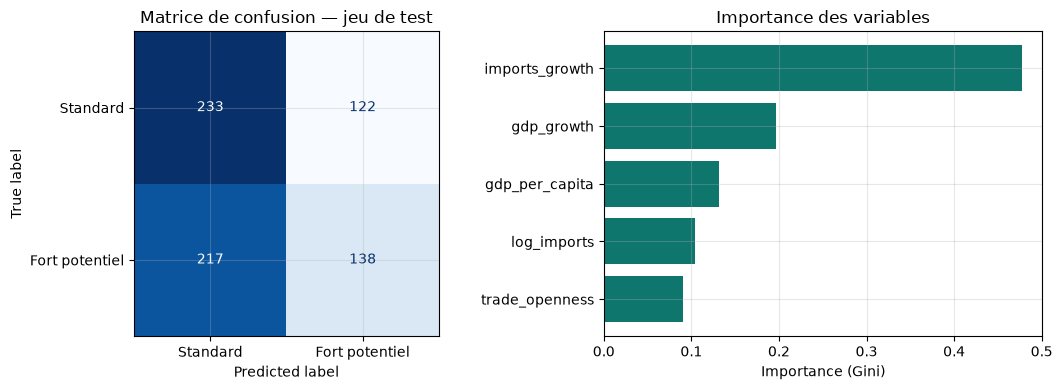

,country,year,imports_growth,future_growth,high_potential,classe_predite,probabilite
1847,Iceland,2021,34.068535,32.455053,1,1,0.644
4404,Zambia,2020,-25.985472,27.472083,1,0,0.387
1022,Croatia,2020,-10.588370,29.591759,1,0,0.216
1598,Greece,2020,-12.609624,40.242934,1,0,0.214
2263,Latvia,2020,-1.612841,30.759742,1,0,0.195
1548,Germany,2020,-8.377234,22.218780,1,0,0.171


In [8]:
# Figure des résultats : matrice de confusion et importance des variables
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Standard", "Fort potentiel"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Matrice de confusion — jeu de test")
imp = pd.Series(metriques["importances"]).sort_values()
axes[1].barh(imp.index, imp.values, color="#0F766E")
axes[1].set(title="Importance des variables", xlabel="Importance (Gini)")
fig.tight_layout()
fig.savefig(FIGURES / "fig4_resultats.png", dpi=150)
plt.show()

# Exemples concrets sur des observations non vues (jeu de test)
exemples = df.loc[~masque_train, ["country", "year", "imports_growth",
                                  "future_growth", "high_potential"]].copy()
exemples["classe_predite"] = y_pred
exemples["probabilite"] = prob.round(3)
display(exemples.sample(n=6, random_state=GRAINE)
        .sort_values("probabilite", ascending=False))

## 7. Résultats et interprétation

| Méthode | F1 validation | F1 test | Accuracy test | Interprétation |
|---|---|---|---|---|
| Référence naïve (classe majoritaire) | 0.0 | 0.0 | 0.5 | Prédit toujours la classe majoritaire : accuracy trompeuse, aucun marché détecté (F1 ≈ 0). |
| Forêt aléatoire (modèle retenu) | 0.545 | 0.449 | 0.523 | Détecte une partie des marchés à fort potentiel ; F1 supérieur à la référence. |

**Chiffres détaillés sur le test :** précision 0.531, rappel 0.389, ROC-AUC 0.561, matrice de confusion [[233, 122], [217, 138]]. Meilleurs hyperparamètres : `max_depth = 3`, `min_samples_leaf = 20`. La figure `figures/fig4_resultats.png` montre la matrice de confusion et l'importance des variables ; « imports_growth » (importance 0.477) est la variable la plus informative.

**Analyse des erreurs, surapprentissage et robustesse :** le F1 de validation (0.545) et le F1 de test (0.449) sont proches : pas de surapprentissage marqué. Les faux positifs correspondent à des pays dont la croissance des importations a finalement été inférieure au seuil malgré des signaux passés favorables ; les faux négatifs à des marchés qui ont accéléré à la suite de chocs non prévisibles. La faible corrélation (0.111) entre croissance passée et future rappelle qu'une part importante de la dynamique commerciale est imprévisible : le modèle reste utile comme **outil de présélection**, pas comme pronostic certain.

**Illustration commerciale :** sur les observations du test, le modèle classe certains pays comme « fort potentiel » avec une probabilité élevée ; un service export peut les placer en priorité dans une liste de prospection, sous réserve d'une vérification qualitative (accords commerciaux, capacité logistique, risque politique).

## 8. Analyse critique

**Limites des données et de leur représentativité :** les indicateurs sont en dollars courants (effets de change et d'inflation), soumis à des révisions rétrospectives et à des différences de méthodologie selon les pays. Le jeu agrégé ne distingue ni produit (code SH) ni partenaire : un pays peut être « à fort potentiel » en moyenne alors qu'un secteur précis se contracte. Enfin, la période de test (2020–2024) inclut la pandémie et les chocs géopolitiques, qui perturbent les régularités passées.

**Limites méthodologiques :** le passage d'une croissance continue à un seuil binaire rend la frontière sensible (10 % plutôt que 8 ou 12 % changerait les étiquettes) ; la faible corrélation entre croissance passée et future limite la performance atteignable. Le F1 et l'accuracy seuls masquent le déséquilibre de classes, d'où le suivi de la précision, du rappel et de l'AUC. La forêt est enfin moins transparente qu'une régression logistique sur l'effet marginal de chaque variable.

**Deux améliorations concrètes :**
1. Enrichir les variables avec des flux bilatéraux et par code produit (UN Comtrade), le taux de change réel et des indicateurs de demande, puis tester un horizon de prévision plus long (3 ans) pour lisser la volatilité annuelle.
2. Comparer avec un gradient boosting et calibrer le seuil de décision probabiliste selon le coût relatif d'un faux positif (prospection inutile) et d'un faux négatif (marché manqué).

## 9. Conclusion

**Réponse explicite à la problématique :** les indicateurs commerciaux et macroéconomiques de l'année `t` ne permettent de prédire qu'imparfaitement le franchissement d'un seuil de croissance des importations en `t+1` : la forêt aléatoire obtient un F1 de 0.449 sur le test, contre 0.0 pour la référence naïve, avec une précision de 0.531 et un rappel de 0.389. L'objectif (F1 ≥ 0,40 et supérieur à la référence) est ATTEINT. Le modèle apporte donc une information utile pour **présélectionner** des marchés, mais ne remplace pas une analyse qualitative.

**Implication pour le commerce international :** intégrer ce score dans un processus de veille commerciale permet de réduire le nombre de destinations à étudier en détail et d'orienter les efforts de prospection vers les marchés les plus dynamiques, tout en gardant à l'esprit la forte part d'incertitude liée aux chocs exogènes.

## 10. Références, reproduction et dépôt

- **Données :** World Bank Open Data — World Development Indicators ; URLs des indicateurs : `https://api.worldbank.org/v2/en/indicator/{NE.IMP.GNFS.CD|NE.TRD.GNFS.ZS|NY.GDP.MKTP.KD.ZG|NY.GDP.PCAP.CD}?downloadformat=csv` ; licence CC BY 4.0 ; extraction le 19/11/2026 ; téléchargement reproductible via `scripts/telecharger_donnees.py`.
- **Documentation :** scikit-learn (`RandomForestClassifier`, `Pipeline`, `ColumnTransformer`, `GridSearchCV`, `DummyClassifier`), pandas, NumPy, matplotlib ;énoncé et guide S7 (A. Larhlimi, ENCG Settat).
- **Dépôt GitHub :** https://github.com/bassema-elhaili/bassema-elhaili
- **Réexécution :** `pip install -r requirements.txt`, puis `python scripts/telecharger_donnees.py` si besoin, puis exécuter les cellules dans l'ordre (graine 42, chemins relatifs, aucune clé d'API).

### Déclaration obligatoire de l'usage de l'IA

| Outil | Usage | Parties concernées | Vérifications personnelles |
|---|---|---|---|
| Assistant IA (OpenCode / Hy4) | Mise en forme du notebook, génération des figures, du rapport et des diapositives à partir du modèle fourni | Code et cellules Markdown ; `DECLARATION_IA.md` | Relecture du code, exécution complète du notebook, contrôle des scores calculés et cohérence avec les figures et le rapport |

### ✅ Contrôle final

- [x] Dix sections du compte rendu remplies ; notebook exécutable de bout en bout
- [x] Source, licence, trois figures interprétées, schéma et résultats calculés
- [x] Export du compte rendu : `rapport/rapport.pdf`
- [x] Six diapositives (PDF + source LaTeX)
- [x] Vidéo de 87 s en 720p : `video/demonstration.mp4` (voix off synthétique, voir `video/README.md`)
- [x] `README.md`, `requirements.txt`, `DECLARATION_IA.md`, `docs/`, `figures/`
- [x] Commits et tag `remise-finale` (à pousser sur GitHub par l'étudiante)
- [ ] Remise officielle : https://forms.gle/SmfW9kbcNbsz4Q8a7